# ПР-4. Линейная регрессия: градиентный спуск на NumPy
Цель: реализовать обучение линейной регрессии вручную (MSE, градиент, цикл спуска), сравнить со scikit-learn и исследовать влияние скорости обучения.
Целевая переменная: логарифм месячного дохода (income).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src.transformers import CreditCleaner

df = pd.read_csv("../data/cs-training.csv", index_col=0)
df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "income",
    "NumberOfOpenCreditLinesAndLoans": "open_credits",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberRealEstateLoansOrLines": "real_estate",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfDependents": "dependents",
})
df.shape

(150000, 11)

In [2]:
df_inc = df[df["income"].notna() & (df["income"] > 0)].copy()
print("Строк с известным доходом > 0:", len(df_inc))

y = np.log(df_inc["income"])
X = df_inc.drop(columns=["income", "default"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

Строк с известным доходом > 0: 118635
(94908, 9) (23727, 9)


## Постановка задачи
- Цель: log(income). Доход сильно скошен (boxplot в ПР-2), логарифм делает распределение ровнее, а ошибка становится относительной.
- Используются только клиенты с известным доходом > 0; нулевой доход считается скрытым пропуском (допущение).
- Признак default не используется: он является исходом, который предсказывается в ПР-5, и при выдаче кредита неизвестен.
- Разбиение train/test выполнено до предобработки, пайплайн обучается только на train.

In [3]:
pipe = Pipeline([
    ("cleaner", CreditCleaner(cap_cols=("utilization", "debt_ratio"))),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# [:, :-1] убирает последний столбец total_late (дублирует три признака просрочек)
Xtr = pipe.fit_transform(X_train)[:, :-1]
Xte = pipe.transform(X_test)[:, :-1]

feature_names = ["utilization", "age", "late_30_59", "debt_ratio",
                 "open_credits", "late_90", "real_estate", "late_60_89", "dependents"]
print(Xtr.shape, Xte.shape, len(feature_names))

(94908, 9) (23727, 9) 9


In [4]:
def add_bias(X):
    """Добавляет столбец из единиц: это свободный член (intercept) модели."""
    return np.c_[np.ones(len(X)), X]

def mse_loss(X, y, w):
    """MSE: средний квадрат ошибки."""
    errors = X @ w - y
    return np.mean(errors ** 2)

def mse_grad(X, y, w):
    """Градиент MSE по весам: (2/n) * X^T * (X w - y)."""
    errors = X @ w - y
    return 2 / len(y) * (X.T @ errors)

def gradient_descent(X, y, lr, n_iter):
    w = np.zeros(X.shape[1])          # стартуем с нулей
    history = []
    for _ in range(n_iter):
        history.append(mse_loss(X, y, w))
        w = w - lr * mse_grad(X, y, w)  # шаг против градиента
    return w, history

Xtr_b = add_bias(Xtr)
Xte_b = add_bias(Xte)
ytr = y_train.to_numpy()
yte = y_test.to_numpy()

## Реализация
Модель: y_pred = X · w (w[0] — свободный член).
Функция потерь: MSE = среднее((X·w − y)²).
Градиент: (2/n) · Xᵀ · (X·w − y) — показывает направление, в котором MSE растёт быстрее всего.
На каждой итерации веса меняются на шаг против градиента: w = w − lr · градиент.

lr=0.001: финальная MSE на train = 1.8230
lr=0.01: финальная MSE на train = 0.4667
lr=0.1: финальная MSE на train = 0.4667
lr=0.5: финальная MSE на train = 0.4667


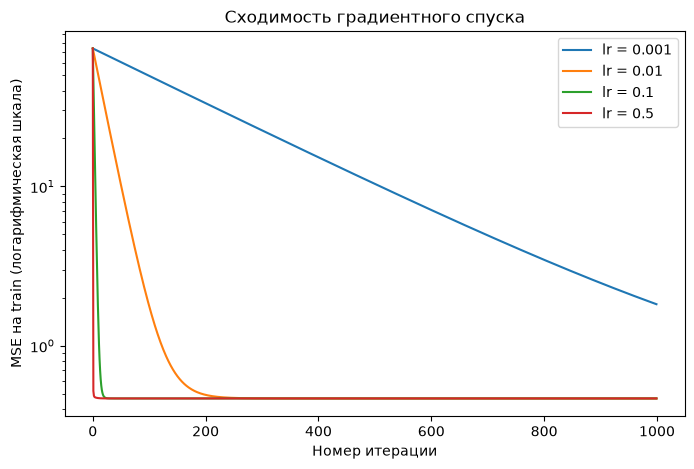

In [5]:
learning_rates = [0.001, 0.01, 0.1, 0.5]
n_iter = 1000
results = {}

for lr in learning_rates:
    w, hist = gradient_descent(Xtr_b, ytr, lr, n_iter)
    results[lr] = (w, hist)
    print(f"lr={lr}: финальная MSE на train = {hist[-1]:.4f}")

plt.figure(figsize=(8, 5))
for lr, (w, hist) in results.items():
    plt.plot(hist, label=f"lr = {lr}")
plt.yscale("log")
plt.title("Сходимость градиентного спуска")
plt.xlabel("Номер итерации")
plt.ylabel("MSE на train (логарифмическая шкала)")
plt.legend()
plt.show()

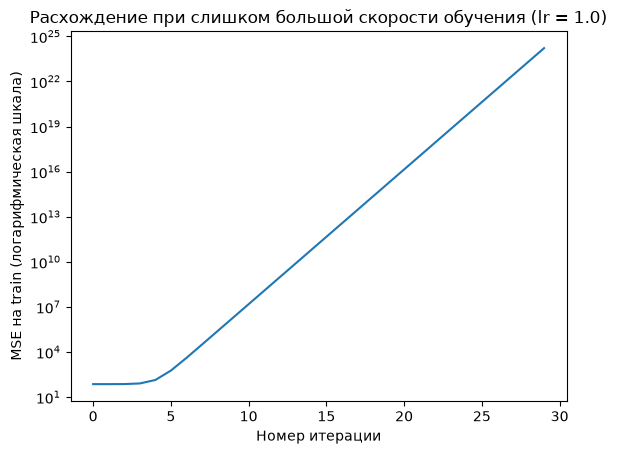

In [6]:
w_bad, hist_bad = gradient_descent(Xtr_b, ytr, lr=1.0, n_iter=30)
plt.plot(hist_bad)
plt.yscale("log")
plt.title("Расхождение при слишком большой скорости обучения (lr = 1.0)")
plt.xlabel("Номер итерации")
plt.ylabel("MSE на train (логарифмическая шкала)")
plt.show()

In [7]:
w_gd = results[0.1][0]       # берём вариант, который хорошо сошёлся

sk = LinearRegression().fit(Xtr, ytr)

compare = pd.DataFrame({
    "признак": ["intercept"] + feature_names,
    "GD (мой)": w_gd,
    "sklearn": np.r_[sk.intercept_, sk.coef_],
})
compare["разница"] = (compare["GD (мой)"] - compare["sklearn"]).abs()
print(compare.round(5))
print("Максимальная разница коэффициентов:", compare["разница"].max())

        признак  GD (мой)  sklearn  разница
0     intercept   8.52323  8.52323      0.0
1   utilization   0.04927  0.04927      0.0
2           age   0.05602  0.05602      0.0
3    late_30_59   0.01320  0.01320      0.0
4    debt_ratio  -0.60893 -0.60893      0.0
5  open_credits   0.18424  0.18424      0.0
6       late_90  -0.00955 -0.00955      0.0
7   real_estate   0.38539  0.38539      0.0
8    late_60_89  -0.00147 -0.00147      0.0
9    dependents   0.11881  0.11881      0.0
Максимальная разница коэффициентов: 3.552713678800501e-15


In [8]:
pred_gd = Xte_b @ w_gd
pred_sk = sk.predict(Xte)

def report(name, pred):
    mae = mean_absolute_error(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    r2 = r2_score(yte, pred)
    # перевод обратно в деньги
    mae_money = mean_absolute_error(np.exp(yte), np.exp(pred))
    print(f"{name}: MAE={mae:.4f} (log), RMSE={rmse:.4f} (log), R2={r2:.4f}, MAE в деньгах={mae_money:.0f}")

report("GD (мой)", pred_gd)
report("sklearn  ", pred_sk)

GD (мой): MAE=0.4424 (log), RMSE=0.6723 (log), R2=0.4733, MAE в деньгах=5820
sklearn  : MAE=0.4424 (log), RMSE=0.6723 (log), R2=0.4733, MAE в деньгах=5820


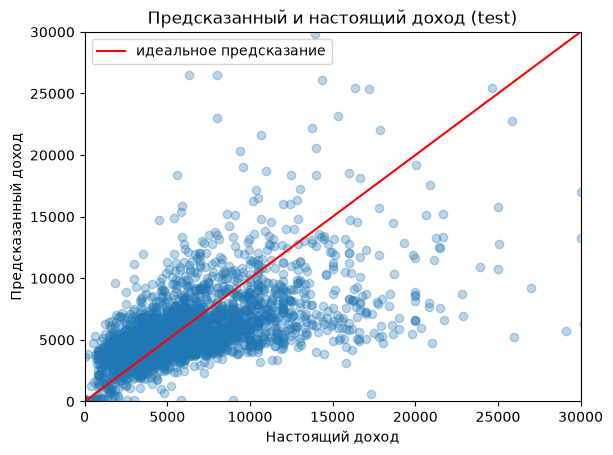

In [9]:
idx = np.random.RandomState(42).choice(len(yte), 3000, replace=False)
plt.scatter(np.exp(yte[idx]), np.exp(pred_gd[idx]), alpha=0.3)
lim = [0, 30000]
plt.plot(lim, lim, color="red", label="идеальное предсказание")
plt.xlim(lim); plt.ylim(lim)
plt.title("Предсказанный и настоящий доход (test)")
plt.xlabel("Настоящий доход")
plt.ylabel("Предсказанный доход")
plt.legend()
plt.show()

## Выводы
**1. Сходимость и скорость обучения.** Проверены четыре значения lr. При lr = 0,01, 0,1 и 0,5 градиентный спуск сошёлся к одному значению MSE на train (0,4667), причём чем больше lr, тем быстрее: примерно 250 итераций, 20–30 итераций и несколько итераций соответственно. При lr = 0,001 шаг слишком мал: за 1000 итераций MSE достигла только 1,82, и обучение не завершилось. При lr = 1,0 метод расходится: MSE растёт с 10¹ до 10²⁵ за 30 итераций, так как слишком большой шаг перепрыгивает минимум. Граница устойчивости лежит между 0,5 и 1,0. Признаки перед обучением были стандартизированы, без этого подходящий lr был бы намного меньше.

**2. Сравнение со scikit-learn.** Коэффициенты собственной реализации и LinearRegression совпадают, максимальная разница 3,6·10⁻¹⁵ (уровень погрешности вычислений). Метрики на test у обеих моделей одинаковые (см. выше). Реализация градиентного спуска корректна.

**3. Качество модели.** (GD (мой): MAE=0.4424 (log), RMSE=0.6723 (log), R2=0.4733, MAE в деньгах=5820
sklearn  : MAE=0.4424 (log), RMSE=0.6723 (log), R2=0.4733, MAE в деньгах=5820). На графике «предсказание против истины» видно, что модель улавливает общий тренд, но предсказания собраны в диапазоне примерно 3 000–10 000, а у клиентов с высоким доходом модель занижает значения. График ограничен значениями до 30 000.

**4. Влияние признаков.** Самый сильный по модулю коэффициент у debt_ratio (−0,61), далее real_estate (+0,39), open_credits (+0,18), dependents (+0,12). Признаки просрочек почти не влияют на доход. Коэффициенты относятся к логарифму дохода и стандартизированным признакам. Связь debt_ratio с доходом частично механическая, так как доход входит в расчёт долговой нагрузки (знаменатель), поэтому её нельзя интерпретировать как причинную.

**5. Допущения.** Использованы только клиенты с известным доходом больше 0 (нулевой доход считается скрытым пропуском). Целевая переменная логарифмирована из-за сильной скошенности дохода. Признак default не использовался.